# Imports

In [1]:
# ---- Device: must run before anything imports jax ----
from devices import use_device
use_device("auto")      # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
# os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false") # If sharing GPU with other processes
os.environ.setdefault("XLA_PYTHON_CLIENT_MEM_FRACTION", "0.2") # If not set, JAX automatically grabs 75% of the GPU's total memory, which can be excessive
# os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + " --xla_gpu_deterministic_ops=true").strip() #force deterministic computation on GPU
import jax, numpyro
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print(jax.default_backend())   # 'gpu' or 'cpu': where JAX runs things by default
print(jax.devices())           # e.g. [CudaDevice(id=0)] for the GPU, or 8 CpuDevices
print("local device count:", jax.local_device_count())

import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value

from likelihood import (
    FD_gaussianlikelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
    wraparound_ratio_posthoc,
)
from model import (
    setup_model,
    make_orthogonal_poly_log_sed,
)
from data import (
    prepare_burst,
)
from run import (
    set_priors,
    run_fit,
    posthoc_samples,
)
from results import (
    save_run,
    to_idata,
)

from plotting import (
    plot_burst_TD, 
    plot_burst_FD,
    model_from_draw,
    plot_fit_TD,
    plot_fit_FD,
    plot_noise_window,
    to_time_domain,
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import arviz as az
import arviz_plots as azp
az.rcParams["plot.max_subplots"] = 300

import random

FRBayes: running on the GPU


/arc/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.2
gpu
[CudaDevice(id=0)]
local device count: 1


# Setup

806 good channels -> 50 blocks of 16 (6 dropped); block span median 6.641 MHz, max 37.109 MHz
noise estimated from 171 of 858 time bins (first 20% of the segment)
Fourier truncation: keeping 52 of 430 bins (up to 5.9 kHz of 48.8 kHz)
weighted mean frequency 596.4 MHz, reference frequency 567.5 MHz
burst data shape = (50, 52)
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


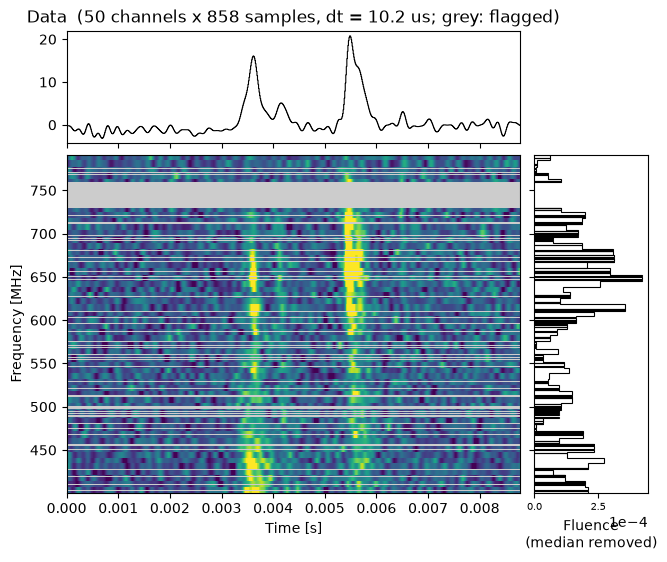

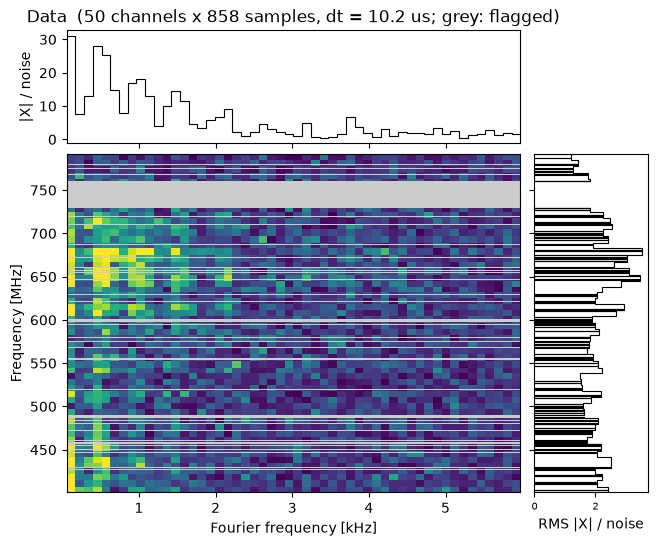

In [2]:
from pathlib import Path

PROJECT  = Path("/arc/home/hsiegel/FRBayes")

event_id = "22310619_BB" #Multi-pulse, 3 pulses
data_path = PROJECT / "data" / f"event_{event_id}.npz"
"22310619_BB"
burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=8,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# event_id = "27687783_BB" #Multi-pulse, many
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=64,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "23438043_BB" # Single-pulse, Narrow SED with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "22154974_BB" # Single-pulse, Broadband with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

print("burst data shape =",burst.data_fd.shape)
plot_burst_TD(burst);                                          # data, in time
plot_burst_FD(burst);                                          # data, in Fourier space

# Run

In [46]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

# n_pulses = 5
# num_chains = 64
n_pulses = 3
num_chains = 64


target_accept_prob = 0.8
seed = 1
num_warmup = 500
num_samples = 200
progress_bar = True
repulsion_dict = {}
# repulsion_dict={"tau_scale":1, "x_min":1}


priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, shrink_sigma_npulses=True)
# priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, delta=dist.Uniform(-5.0, -3.0))
# priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, gamma_range=(-10.0, 30.0), beta_range=(-10.0, 30.0))


extend_duration = False # Padding against wraparound: off by default. Turn on when a pulse reaches the window edge.
# fit_fn = single_pulse_fn.extend_model_duration(burst, priors) if extend_duration else single_pulse_fn
fit_fn = single_pulse_fn.extend_model_duration(factor=2) if extend_duration else single_pulse_fn

mcmc = run_fit(burst, fit_fn, priors, FD_gaussianlikelihood, seed=seed,
               num_chains=num_chains, n_pulses=n_pulses, target_accept_prob=target_accept_prob,
               num_warmup=num_warmup, num_samples=num_samples, progress_bar=progress_bar,
               repulsion=repulsion_dict)#, shared_params=("DM", "tau_ref", "delta"))
samples = mcmc.get_samples()

mcmc_data = to_idata(mcmc, log_likelihood={}, posterior_predictive={})
# idata = save_run(None, mcmc, burst, priors, data_path,
#                  single_pulse_fn=fit_fn, extra_samples=extra, event_id=event_id)

prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011280245631210115
prior being set with bounds:
c1_min = -1.922094 
c1_max = 38.441883 
c2_min = -5.0560703 
c2_max = 0.25280353
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: Uniform(low=2.68908e-05, high=0.000488107)
tau_ref: Uniform(low=0, high=0.00112802)
c1: Uniform(low=-1.92209, high=38.4419)
c2: Uniform(low=-5.05607, high=0.252804)
A_snr: HalfNormal(scale=100)
run_fit seed: 1
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [06:43<00:00,  1.74it/s]


sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


In [47]:
div = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["diverging"]).astype(bool)   # (chain, draw)
print("divergences per chain:", div.sum(axis=1))
# s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
# snr_on = 3.0                                                       # whatever you used
# checks = {
#     "closest-pair x":         s["toa_separation"].min(axis=-1),
#     "smallest A_snr":         s["A_snr"].min(axis=-1),
#     "pulse near snr_on (frac)": (np.abs(s["A_snr"] - snr_on) < 1.0).any(axis=-1).astype(float),
# }
# for name, v in checks.items():
#     print(f"{name:25s} divergent: {np.median(v[div]) if 'frac' not in name else v[div].mean():.2f}   "
#           f"others: {np.median(v[~div]) if 'frac' not in name else v[~div].mean():.2f}")

divergences per chain: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0 22  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  4  0  0 68  0  0  0  0  0  0  0  2]


In [48]:
steps = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])     # (chain, draw), after warmup
depth = np.ceil(np.log2(steps + 1)).astype(int)
max_depth = 10                                                                    # whatever the run used
for c in range(steps.shape[0]):
    print(f"chain {c}: median depth {np.median(depth[c]):.0f}   max {depth[c].max()}   "
          f"hit the limit {np.mean(steps[c] >= 2 ** max_depth - 1):.0%}   mean steps {steps[c].mean():.0f}")

chain 0: median depth 4   max 5   hit the limit 0%   mean steps 16
chain 1: median depth 4   max 6   hit the limit 0%   mean steps 20
chain 2: median depth 5   max 7   hit the limit 0%   mean steps 27
chain 3: median depth 4   max 5   hit the limit 0%   mean steps 16
chain 4: median depth 5   max 5   hit the limit 0%   mean steps 28
chain 5: median depth 8   max 8   hit the limit 0%   mean steps 255
chain 6: median depth 4   max 6   hit the limit 0%   mean steps 21
chain 7: median depth 5   max 7   hit the limit 0%   mean steps 32
chain 8: median depth 4   max 6   hit the limit 0%   mean steps 18
chain 9: median depth 4   max 5   hit the limit 0%   mean steps 17
chain 10: median depth 4   max 6   hit the limit 0%   mean steps 18
chain 11: median depth 7   max 8   hit the limit 0%   mean steps 161
chain 12: median depth 5   max 6   hit the limit 0%   mean steps 31
chain 13: median depth 4   max 5   hit the limit 0%   mean steps 15
chain 14: median depth 4   max 8   hit the limit 0%   me

In [49]:
ns = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])
print("leapfrogs per iteration, median per chain:", np.median(ns, axis=1), "  max:", ns.max())
print("step size per chain:", np.asarray(mcmc.last_state.adapt_state.step_size))

leapfrogs per iteration, median per chain: [ 15.  15.  31.  15.  31. 255.  15.  31.  15.  15.  15. 127.  31.  15.
  15.  15.  15.  15.  15.  15.  15. 255.  31.  15.  15.  47.  15.  15.
  15.  63. 255.  15.  15.  15.  15.  15.  63.  15.  15.  15. 255.  15.
  63.  15.  15. 127. 255.  15.  15.  15.  31.  15.  31.  15.  15.  15.
  15.  15.  79.  15.  31.  63.  15.  63.]   max: 255
step size per chain: [0.21772468 0.21103373 0.17535503 0.22985552 0.14274131 0.0057984
 0.20705526 0.1214463  0.19964516 0.21970049 0.22480103 0.02346857
 0.1252635  0.22731578 0.20786381 0.19717889 0.23372681 0.22806123
 0.21681392 0.21588218 0.21886693 0.01145272 0.1803909  0.20694268
 0.18839999 0.08070733 0.21348068 0.21747221 0.21211357 0.07381866
 0.01395402 0.19235818 0.19725136 0.20506944 0.22641414 0.2008275
 0.04789921 0.19548374 0.21689191 0.2229549  0.00546921 0.27797976
 0.08016758 0.23192245 0.20500915 0.02530872 0.01700997 0.21251564
 0.22944221 0.20620213 0.18141973 0.20899315 0.16728012 0.2081430

In [50]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,89.470,110.013,2.249,0.000,0.000
A[1],0.000,0.000,0.000,0.000,85.278,115.015,2.175,0.000,0.000
A[2],0.000,0.000,0.000,0.000,88.519,119.229,2.029,0.000,0.000
A_snr[0],39.851,23.533,1.321,60.474,83.496,82.651,2.240,2.880,1.215
A_snr[1],38.597,20.070,5.113,60.018,77.587,131.814,2.684,2.455,1.297
A_snr[2],29.467,21.913,5.312,59.757,82.929,136.541,2.271,2.681,0.697
DM[0],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM[1],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM[2],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM_shared,-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001


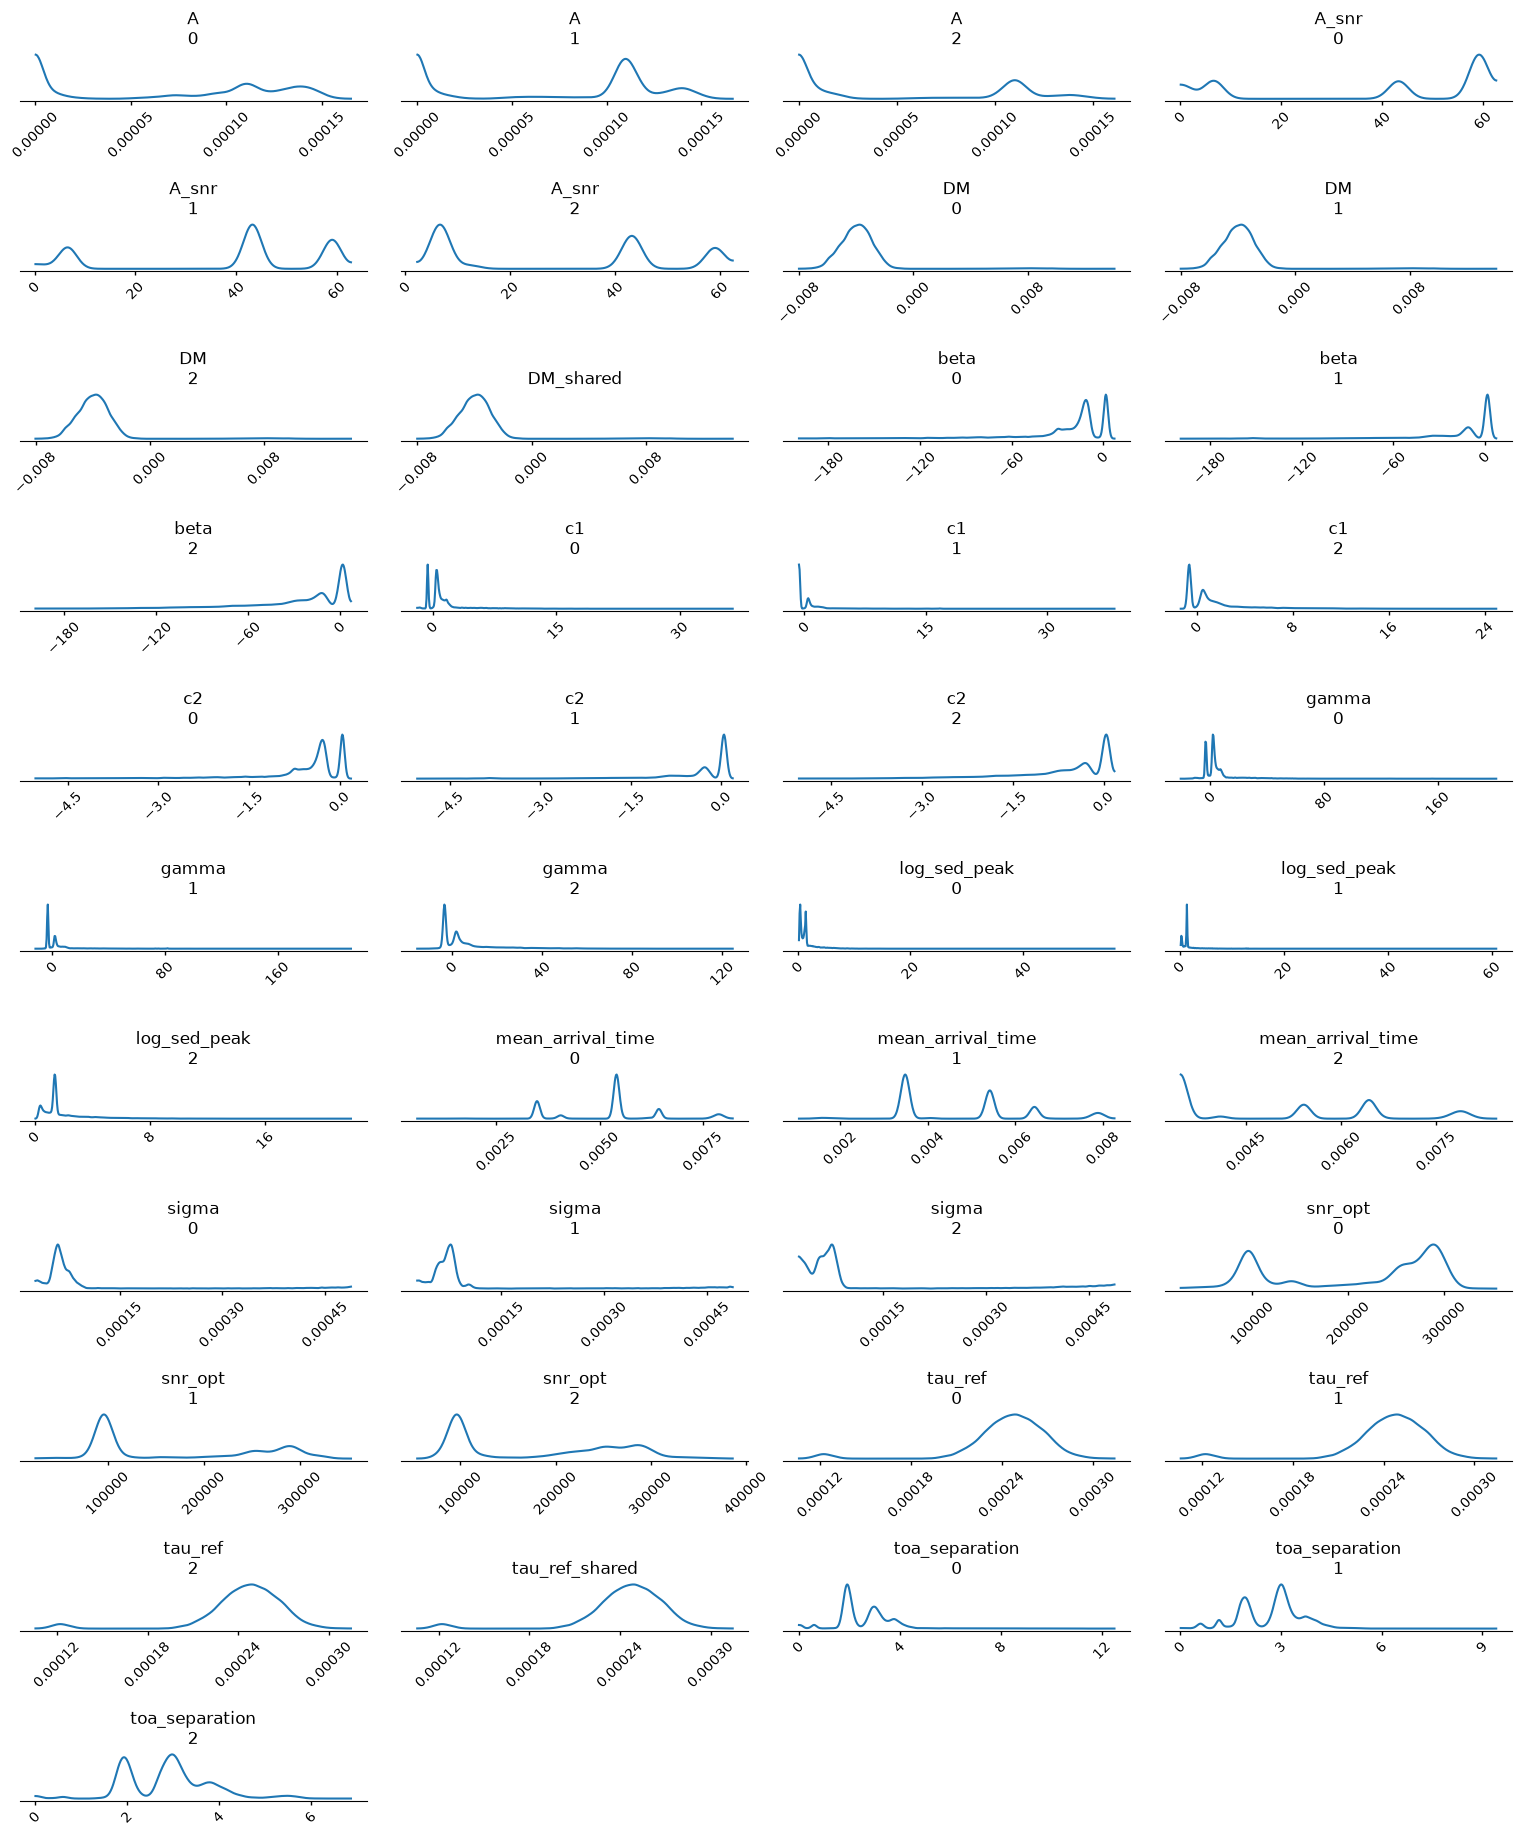

In [51]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

In [52]:
# import warnings

# warnings.filterwarnings(
#     "ignore",
#     message="Explicitly requested dtype.*is not available",
#     category=UserWarning,
# )

# azp.plot_trace(mcmc_data)

# # 2. Clean up x-axis tick clutter across all generated subplots
# for ax in plt.gcf().axes:
#     ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
#     ax.tick_params(axis="x", rotation=45)

# plt.tight_layout()
# plt.show()

In [53]:
pe = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["potential_energy"])
s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
active = s["A_snr"] > 3.0
for c in np.argsort(pe.mean(axis=1)):                      # best (lowest -log post) first
    t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)
    print(f"chain {c}: -log post {pe[c].mean():9.1f} ± {pe[c].std():4.1f}   "
          f"active {active[c].sum(-1).mean():.1f}   t [ms] {np.round(np.sort(t) * 1e3, 2)}   "
          f"A_snr {np.round(np.median(s['A_snr'][c], axis=0), 1)}")

chain 41: -log post    3734.4 ±  2.5   active 3.0   t [ms] [3.52 4.09 5.46]   A_snr [43.3 58.5 12.3]
chain 39: -log post    3734.7 ±  2.6   active 3.0   t [ms] [3.52 4.09 5.46]   A_snr [43.3 58.6 12.5]
chain 45: -log post    3752.9 ±  2.6   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [59.1 42.9  6.9]
chain 7: -log post    3753.3 ±  3.2   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [59.1 43.1  6.7]
chain 28: -log post    3753.4 ±  2.9   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [ 6.8 42.9 59.1]
chain 54: -log post    3753.5 ±  2.7   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [ 6.9 59.1 43. ]
chain 6: -log post    3753.5 ±  2.8   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [ 6.8 42.9 59. ]
chain 58: -log post    3753.5 ±  2.9   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [59.  43.1  6.9]
chain 19: -log post    3753.5 ±  3.0   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [59.   6.8 42.8]
chain 35: -log post    3753.5 ±  3.0   active 3.0   t [ms] [3.49 5.41 6.44]   A_snr [59.   6.

/tmp/ipykernel_19318/2849936320.py:5: RuntimeWarning: All-NaN slice encountered
  t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)


In [54]:
key = jax.random.PRNGKey(7)

In [64]:
samples = mcmc.get_samples()

mcmc_data = to_idata(mcmc, log_likelihood={}, posterior_predictive={})


sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


draw 11057 (chain 55)
chain 55, draw 11057:  A_snr [58.8  6.2 41.9]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


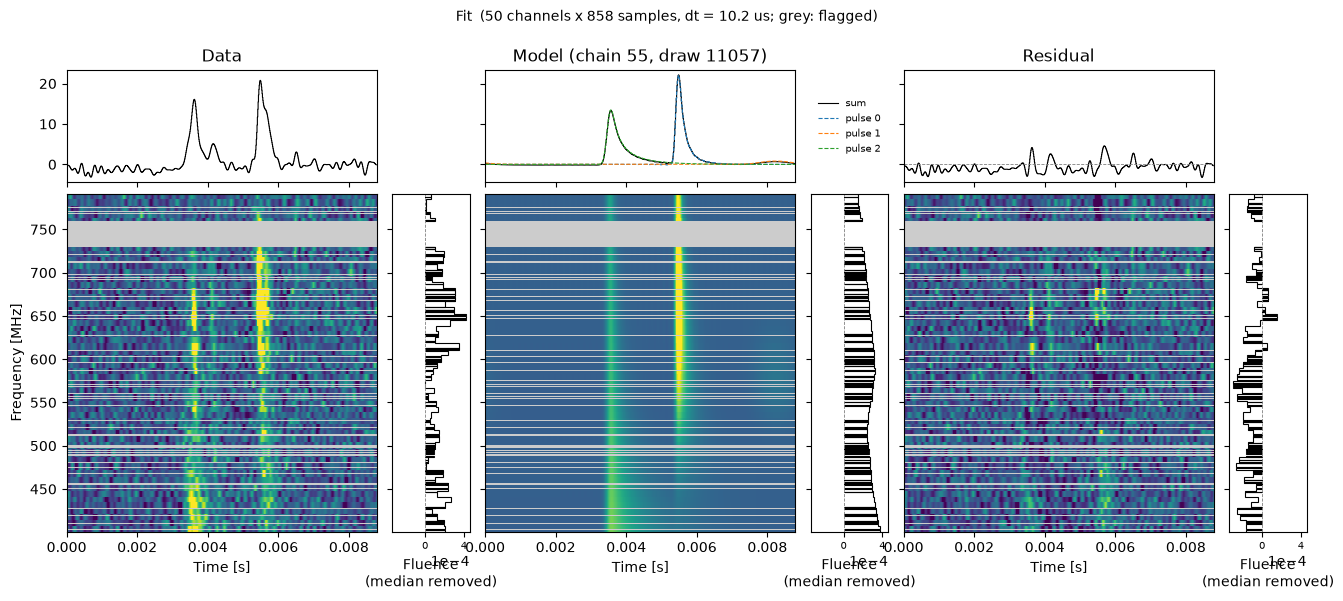

whitened residual sd: 1.182  (expect 1)


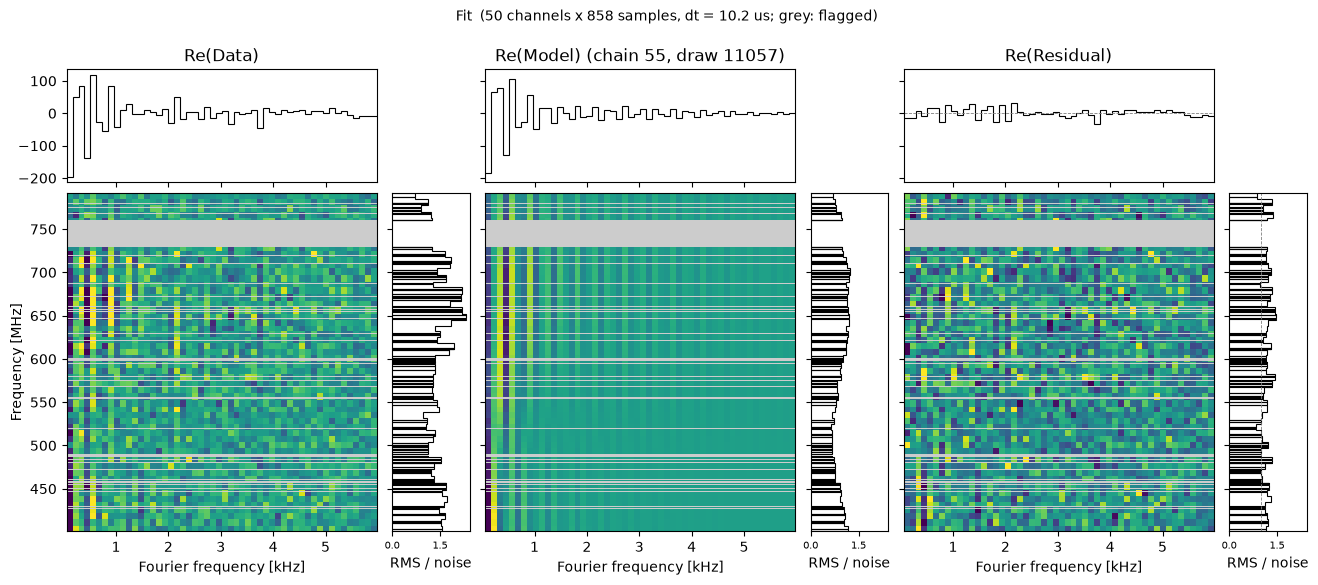

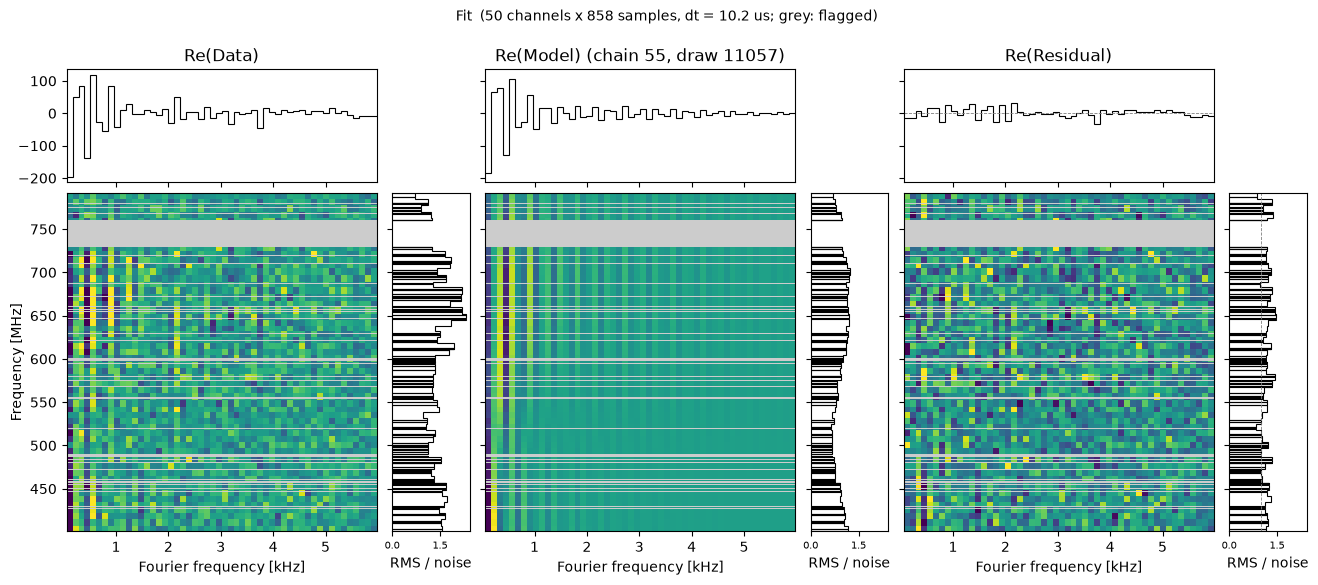

In [67]:
chain = 55                     # the chain to draw from
n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
print(f"draw {draw_idx} (chain {chain})")

print(f"chain {chain}, draw {draw_idx}:  A_snr", np.round(np.asarray(samples["A_snr"][draw_idx]).reshape(-1), 1))

M_FD, M_FD_pulses = model_from_draw(fit_fn, samples, draw_idx)
plot_fit_TD(burst, M_FD, M_FD_pulses, title_model=f"Model (chain {chain}, draw {draw_idx})")
plot_fit_FD(burst, M_FD, title_model=f"Re(Model) (chain {chain}, draw {draw_idx})")

draw 1169 (chain 5)
chain 5, draw 1169:  A_snr [59.4 43.6  6.4]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


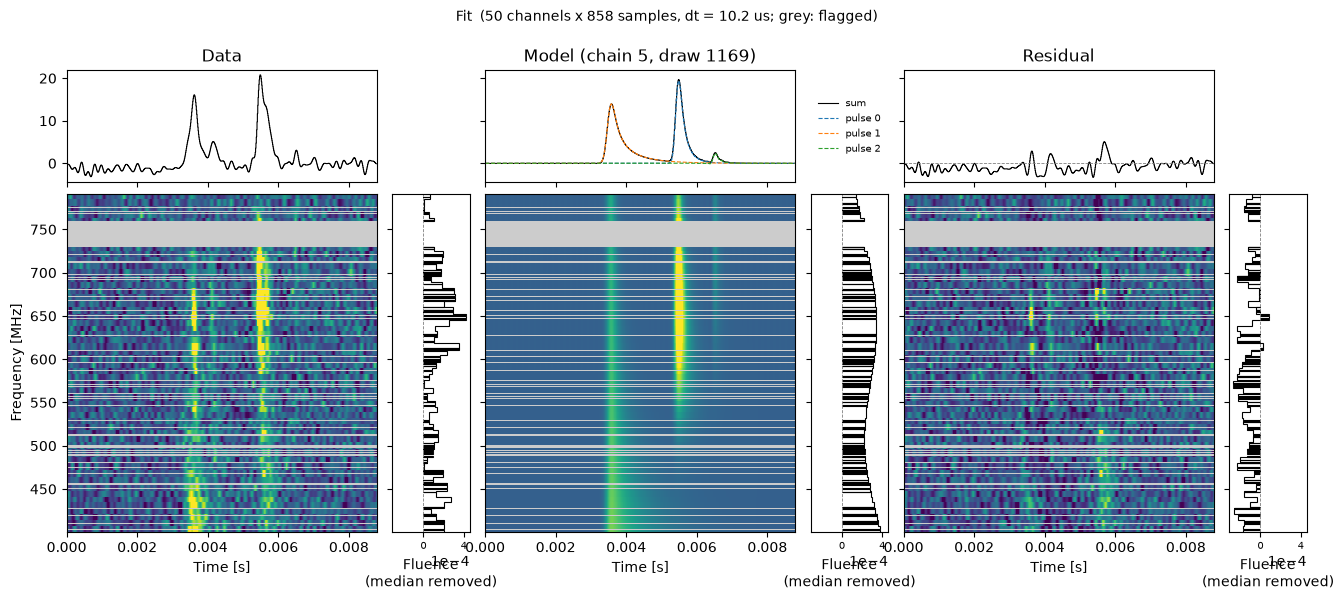

whitened residual sd: 1.190  (expect 1)


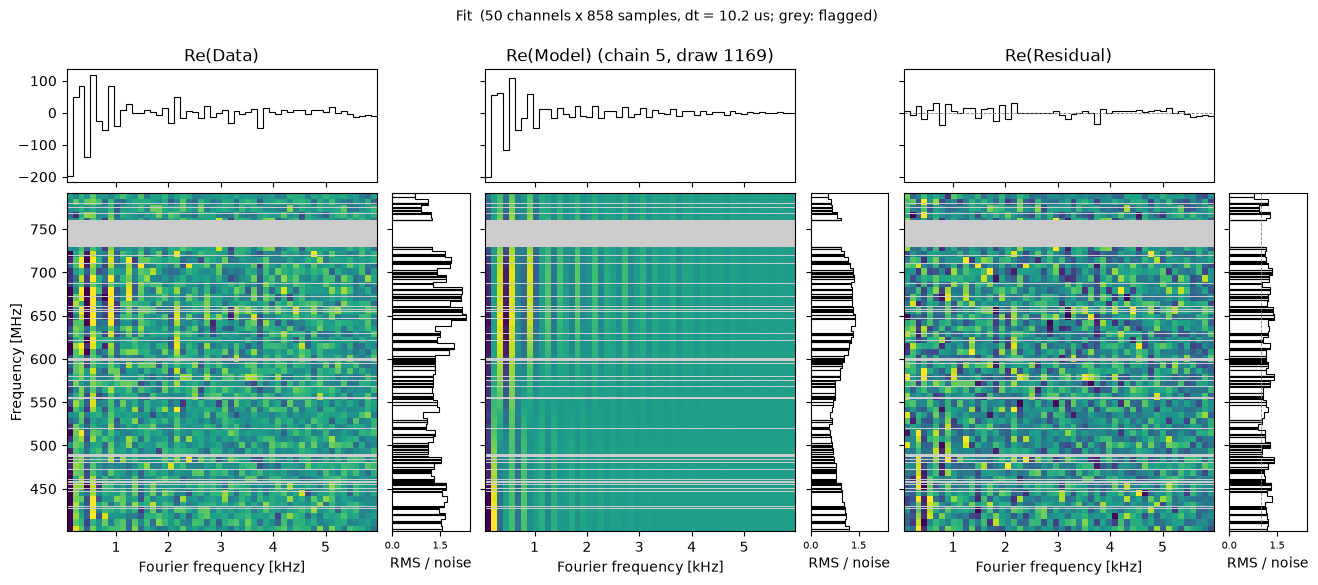

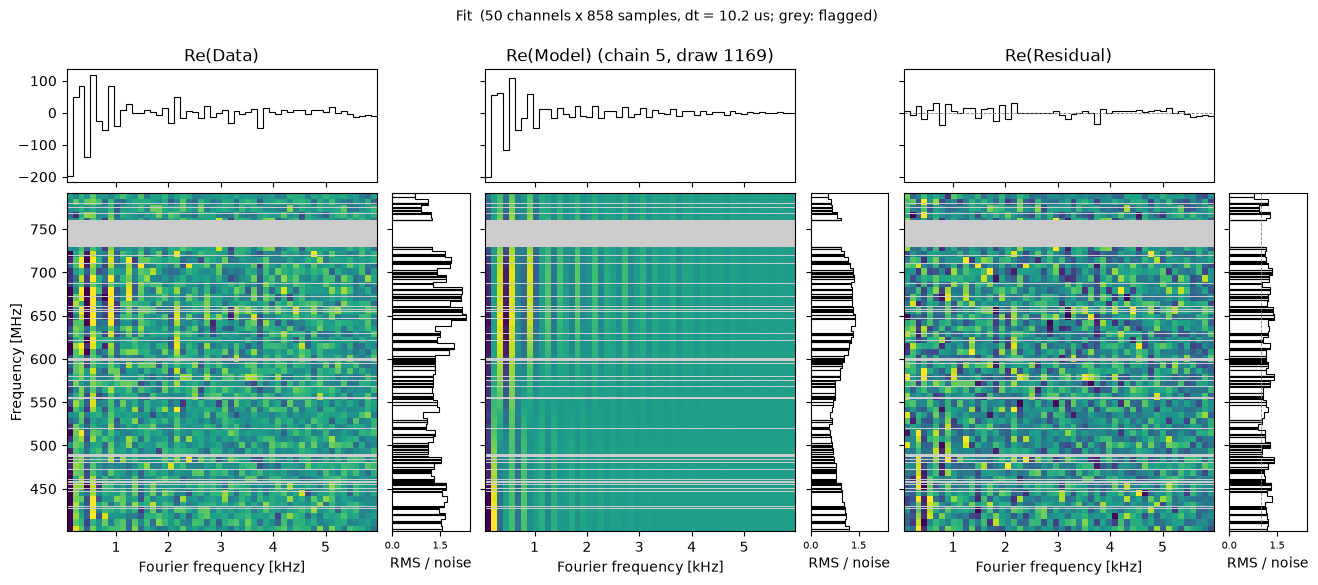

In [57]:
chain = 5                       # the chain to draw from
n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
print(f"draw {draw_idx} (chain {chain})")

print(f"chain {chain}, draw {draw_idx}:  A_snr", np.round(np.asarray(samples["A_snr"][draw_idx]).reshape(-1), 1))

M_FD, M_FD_pulses = model_from_draw(fit_fn, samples, draw_idx)
plot_fit_TD(burst, M_FD, M_FD_pulses, title_model=f"Model (chain {chain}, draw {draw_idx})")
plot_fit_FD(burst, M_FD, title_model=f"Re(Model) (chain {chain}, draw {draw_idx})")

noise window: first 171 of 858 samples (to 1.75 ms)
  profile mean over the last third of the window: +2.02 standard errors (emission leaking in shows as clearly positive)
  profile sd in the window: 0.99   in the last 20% of the segment: 1.10   (expect 1)


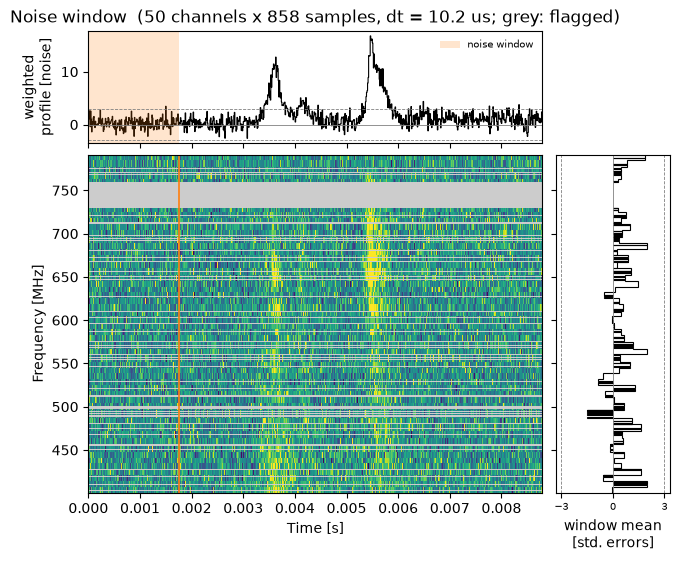

In [58]:
fig = plot_noise_window(burst)

In [59]:
# from postprocess import order_pulses
# samples = order_pulses(mcmc.get_samples(group_by_chain=True))   # or mcmc.get_samples()

In [60]:
# samples

In [61]:
# chain = 12                                                           # the chain to test
# n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
# draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
# M_FD, _ = model_from_draw(fit_fn, samples, draw_idx)
# print(f"chain {chain}, draw {draw_idx}")

R = np.asarray(burst.data_fd) - np.asarray(M_FD)
r = np.asarray(to_time_domain(burst, jnp.asarray(R))) / np.asarray(burst.sigma_noise_td).reshape(-1, 1)
w = np.asarray(burst.channel_weights)
prof = np.tensordot(np.sqrt(w), r, axes=(0, 0))                     # channel-weighted residual profile
prof /= prof[: burst.n_noise_bins].std()                             # unit variance off-pulse, cancelling noise-level errors

K = 20                                                               # window, a few pulse widths in samples
excess = np.convolve(prof ** 2 - 1.0, np.ones(K), mode="valid")      # SNR^2 of residual structure per window
i = int(np.argmax(excess))
print(f"residual SNR {np.sqrt(max(excess[i], 0)):.1f} in the window starting {burst.times[i] * 1e3:.2f} ms  (threshold 10)")

residual SNR 31.1 in the window starting 5.61 ms  (threshold 10)


In [62]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import arviz_plots as azp
from arviz_base import from_dict

# 1. pool within modes, stack between modes
samples = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}   # (chains, draws, ...)
log_lik = pointwise_log_lik(burst, single_pulse_fn, samples, thin=1)
posterior, info = combine_chains(samples, log_lik)        # prints the modes, their weights and draws
print("draws per chain:", dict(enumerate(np.bincount(info["chain"], minlength=len(log_lik)))))

# 2. marginals of the combined posterior
post = {}
for k in ("mean_arrival_time", "sigma", "tau_ref", "DM", "A_snr", "gamma", "beta", "c1", "c2"):
    if k not in posterior:
        continue
    v = np.asarray(posterior[k])
    if v.ndim == 2 and np.allclose(v, v[:, :1]):           # shared parameter, stored once per pulse
        v = v[:, 0]
    post[k] = v[None]                                        # chain axis of length 1
azp.plot_dist(from_dict({"posterior": post}), stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
    for collection in list(ax.collections):
        collection.remove()
plt.tight_layout()
plt.subplots_adjust(wspace=0.1, hspace=2.5)
plt.draw()

ValueError: mode_weights='peak' needs potential_energy: mcmc.get_extra_fields(group_by_chain=True)['potential_energy'].

In [ ]:
import numpy as np
from postprocess import excess_power_search
from plotting import model_from_draw

epsilon, n_test = 0.2, 10
rng = np.random.default_rng(0)
for d in rng.choice(len(posterior["mean_arrival_time"]), n_test, replace=False):
    M_FD, M_FD_pulses = model_from_draw(single_pulse_fn, posterior, d)
    ep = excess_power_search(burst, np.asarray(M_FD), epsilon=epsilon, verbose=False)
    t = ep["tiles"][0]
    print(f"draw {d}: {'ADD' if ep['add_pulse'] else 'stop'}  p={ep['p']:.2g}  "
          f"unexplained SNR {t['snr_unexplained']:.1f} at {t['t_range'][0]*1e3:.1f}-{t['t_range'][1]*1e3:.1f} ms, "
          f"{t['channel_range'][0]:.0f}-{t['channel_range'][1]:.0f} MHz")

In [ ]:
import importlib, postprocess, plotting
importlib.reload(postprocess); importlib.reload(plotting)
from postprocess import excess_power_search
from plotting import model_from_draw, plot_residual_tiles

d = 0                                                         # stacked draw to test
M_FD, M_FD_pulses = model_from_draw(single_pulse_fn, posterior, d)
ep = excess_power_search(burst, np.asarray(M_FD), epsilon=0.2)
plot_residual_tiles(burst, M_FD, ep)

# 1 vs n pulse comparisons

prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011280245631210115
prior being set with bounds:
c1_min = -1.922094 
c1_max = 38.441883 
c2_min = -5.0560703 
c2_max = 0.25280353
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: Uniform(low=2.68908e-05, high=0.00146432)
tau_ref: Uniform(low=0, high=0.00112802)
c1: Uniform(low=-1.92209, high=38.4419)
c2: Uniform(low=-5.05607, high=0.252804)
A_snr: HalfNormal(scale=100)
run_fit seed: 2
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [00:39<00:00, 17.60it/s]


group_chains: 64 chains -> 2 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [18, 27, 30, 38, 45, 48, 49, 61, 62], largest R-hat within 1.042
  mode 1: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29, 31, 32, 33, 34, 35, 36, 37, 39, 40, 41, 42, 43, 44, 46, 47, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 63], largest R-hat within 1.046
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.756), 1800 draws from 9 chain(s)
  mode 1: peak log post -950.2, mean log-lik -948.5, weight 0.000 (stacking would give 0.244), 0 draws from 55 chain(s)
combine_chains: 1800 draws in all
Residual test (tolerating 20% model error): strongest unexplained residual SNR 33.1 at 2.75-3.84 ms, 404-788 MHz (residual SNR 33.1, model SNR there 1.8)
  -> ADD A PULSE (p = 1.3e-153 after 203870 boxes)
  note: noise is 1.27 x sigma_noise_fd; rescaled before testing
prior bei

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [03:19<00:00,  3.50it/s]


group_chains: 64 chains -> 3 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 16, 17, 19, 20, 21, 22, 23, 24, 26, 27, 29, 30, 31, 34, 35, 37, 38, 39, 40, 42, 43, 44, 45, 46, 48, 49, 50, 54, 55, 58, 61, 63], largest R-hat within 1.133
  mode 1: chains [11, 15, 18, 25, 28, 33, 36, 41, 47, 51, 52, 53, 56, 57, 59, 60, 62], largest R-hat within 1.113
  mode 2: chains [32]
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.615), 9200 draws from 46 chain(s)
  mode 1: peak log post -841.2, mean log-lik -841.9, weight 0.000 (stacking would give 0.219), 0 draws from 17 chain(s)
  mode 2: peak log post -1646.2, mean log-lik -1641.3, weight 0.000 (stacking would give 0.166), 0 draws from 1 chain(s)
combine_chains: 9200 draws in all
box 2.75-3.84 ms, 404-788 MHz (SNR 33.1): model change SNR 27.5, efficiency +1.27 -> explained
box 5.49-7.69 ms, 404-515 MHz (SNR 17.0): m

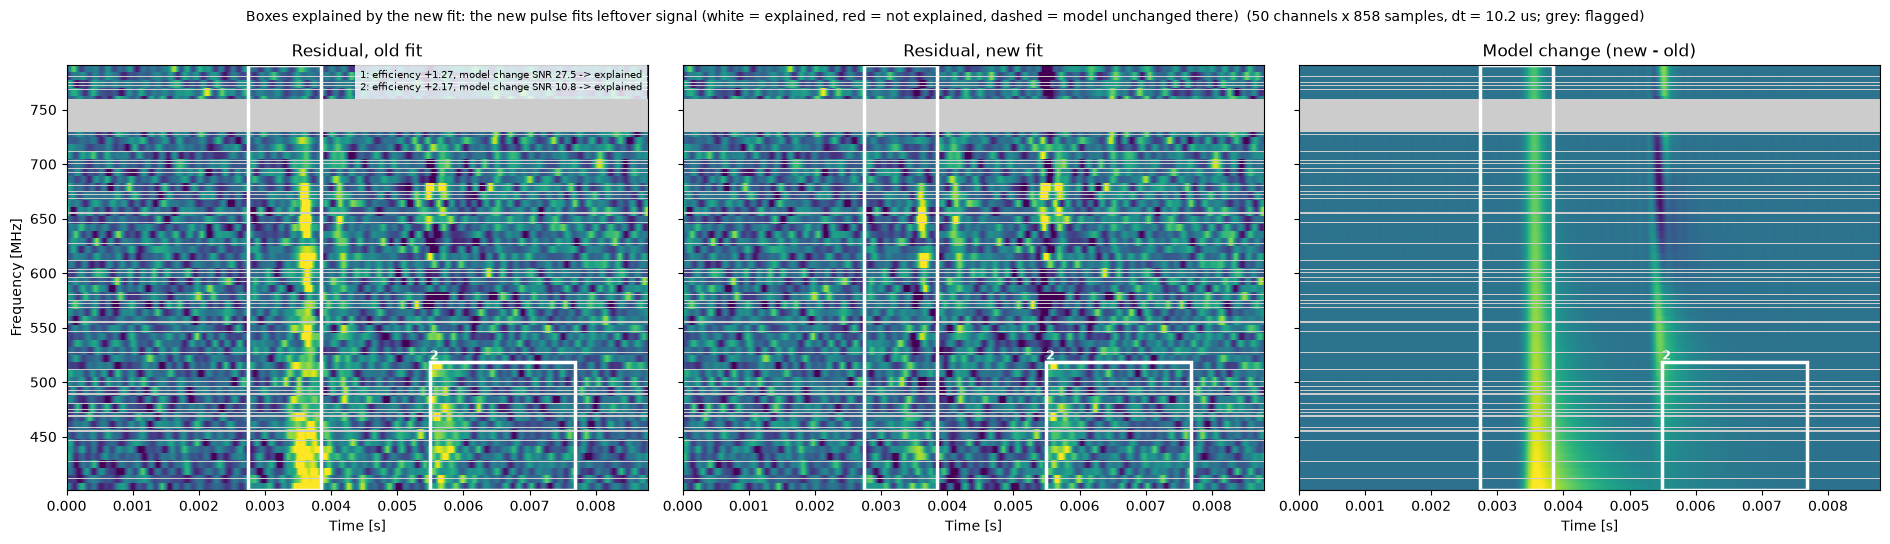

1 -> 2 pulses: delta ELPD = 812.8, explains leftover signal: True -> accept
Residual test (tolerating 20% model error): strongest unexplained residual SNR 33.5 at 2.06-6.45 ms, 404-788 MHz (residual SNR 35.9, model SNR there 64.3)
  -> ADD A PULSE (p = 1.2e-47 after 203870 boxes)
prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011280245631210115
prior being set with bounds:
c1_min = -1.922094 
c1_max = 38.441883 
c2_min = -5.0560703 
c2_max = 0.25280353
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: Uniform(low=2.68908e-05, high=0.000488107)
tau_ref: Uniform(low=0, high=0.00112802)
c1: Uniform(low=-1.92209, high=38.4419)
c2: Uniform(low=-5.05607, high=0.252804)
A_snr: HalfNormal(scale=100)
run_fit seed: 2
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [06:48<00:00,  1.71it/s]


group_chains: 64 chains -> 13 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [1, 17, 21, 24, 27, 29, 33, 34, 37, 38, 39, 41, 42, 43, 45, 49, 52, 55, 56, 57, 59, 60, 62], largest R-hat within 1.117
  mode 1: chains [13]
  mode 2: chains [4, 6, 8, 9, 10, 12, 18, 20, 23, 25, 26, 30, 31, 32, 35, 36, 44, 46, 47, 48, 50, 51, 53, 54, 58, 61, 63], largest R-hat within 1.060
  mode 3: chains [7]
  mode 4: chains [15]
  mode 5: chains [40]
  mode 6: chains [5]
  mode 7: chains [22]
  mode 8: chains [2]
  mode 9: chains [19]
  mode 10: chains [0, 3, 14, 16], largest R-hat within 1.102
  mode 11: chains [11]
  mode 12: chains [28]
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 0.726 (stacking would give 0.000), 3313 draws from 23 chain(s)
  mode 1: peak log post -10.2, mean log-lik -1.1, weight 0.000 (stacking would give 0.319), 0 draws from 1 chain(s)
  mode 2: peak log post -2.1, mean log-lik -2.8, weight 0.092 (stacking would give 0.

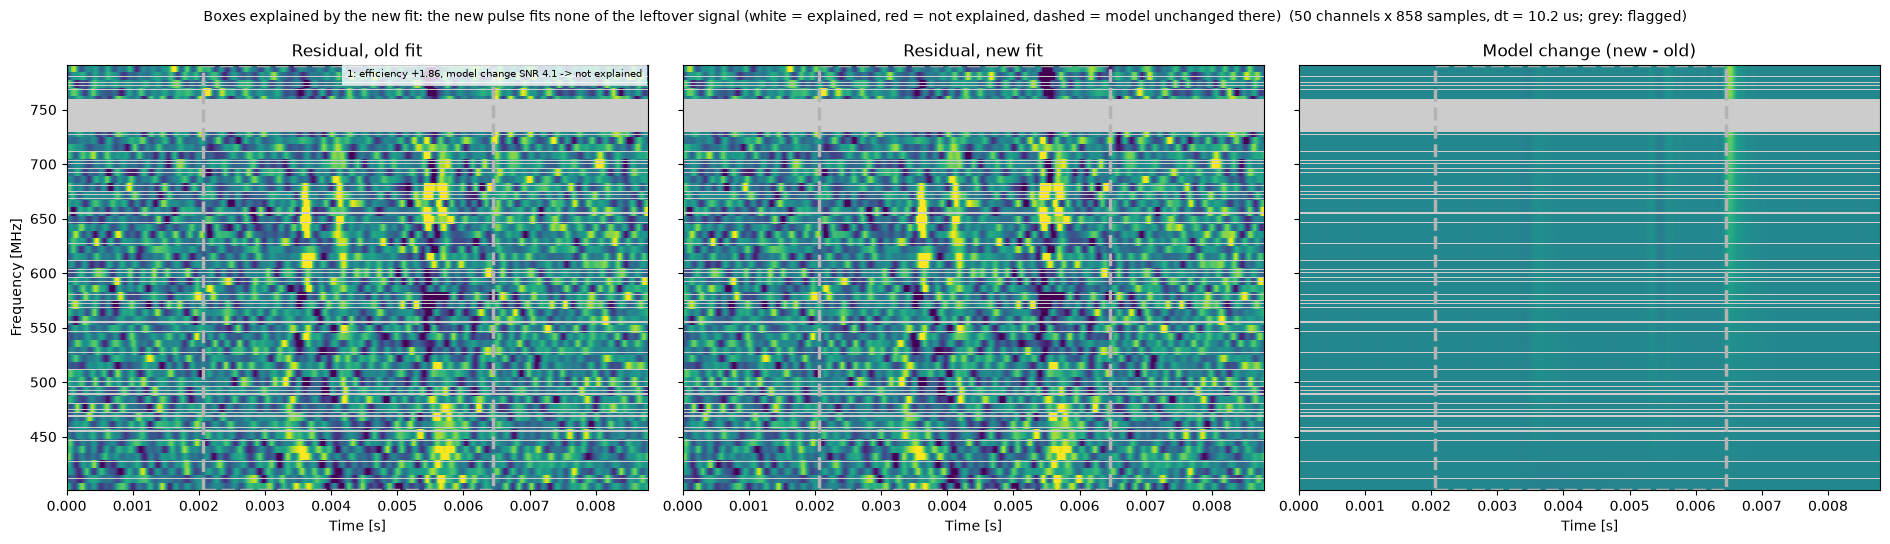

2 -> 3 pulses: delta ELPD = 2.8, explains leftover signal: False -> reject
final: 2 pulse(s)


In [69]:
import numpy as np
from model import setup_model, make_orthogonal_poly_log_sed
from run import set_priors, run_fit
from likelihood import FD_gaussianlikelihood
from postprocess import (pointwise_log_lik, combine_chains, excess_power_search, boxes_explained,
                         _loo_by_observation)
from plotting import model_from_draw, plot_boxes_explained

constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

def fit(n):
    priors = set_priors(burst, single_pulse_fn, n, s_opt=100.0, shrink_sigma_npulses=True)
    mcmc = run_fit(burst, single_pulse_fn, priors, FD_gaussianlikelihood, n_pulses=n,
                   num_chains=64, seed=2, repulsion={})
    s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
    U = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["potential_energy"])
    ll = pointwise_log_lik(burst, single_pulse_fn, s, thin=1)          # thin=1: indices below need it
    post, info = combine_chains(s, ll, U)                              # peak-posterior mode weights
    ll_post = ll[info["chain"], info["draw"]]                          # log-lik of the combined draws
    best = int(np.argmax(ll_post.sum(axis=1)))                         # draw used for the model
    M, _ = model_from_draw(single_pulse_fn, post, best)
    return dict(post=post, info=info, M=np.asarray(M), elpd=_loo_by_observation(ll_post)[0].sum())

fits, n_final = {1: fit(1)}, 1
for n in range(2, 6):
    ep = excess_power_search(burst, fits[n - 1]["M"])                  # leftover signal after n-1 pulses
    if not ep["add_pulse"]:
        break
    fits[n] = fit(n)
    check = boxes_explained(burst, fits[n - 1]["M"], fits[n]["M"], ep)
    plot_boxes_explained(burst, fits[n - 1]["M"], fits[n]["M"], check)
    d_elpd = fits[n]["elpd"] - fits[n - 1]["elpd"]
    accept = check["any_removed"] and d_elpd >= 50
    print(f"{n - 1} -> {n} pulses: delta ELPD = {d_elpd:.1f}, explains leftover signal: "
          f"{check['any_removed']} -> {'accept' if accept else 'reject'}")
    if not accept:
        break
    n_final = n
print(f"final: {n_final} pulse(s)")
posterior = fits[n_final]["post"]

t [ms] [3.489 5.414 6.449]   A_snr [43.1 58.9  8.2]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


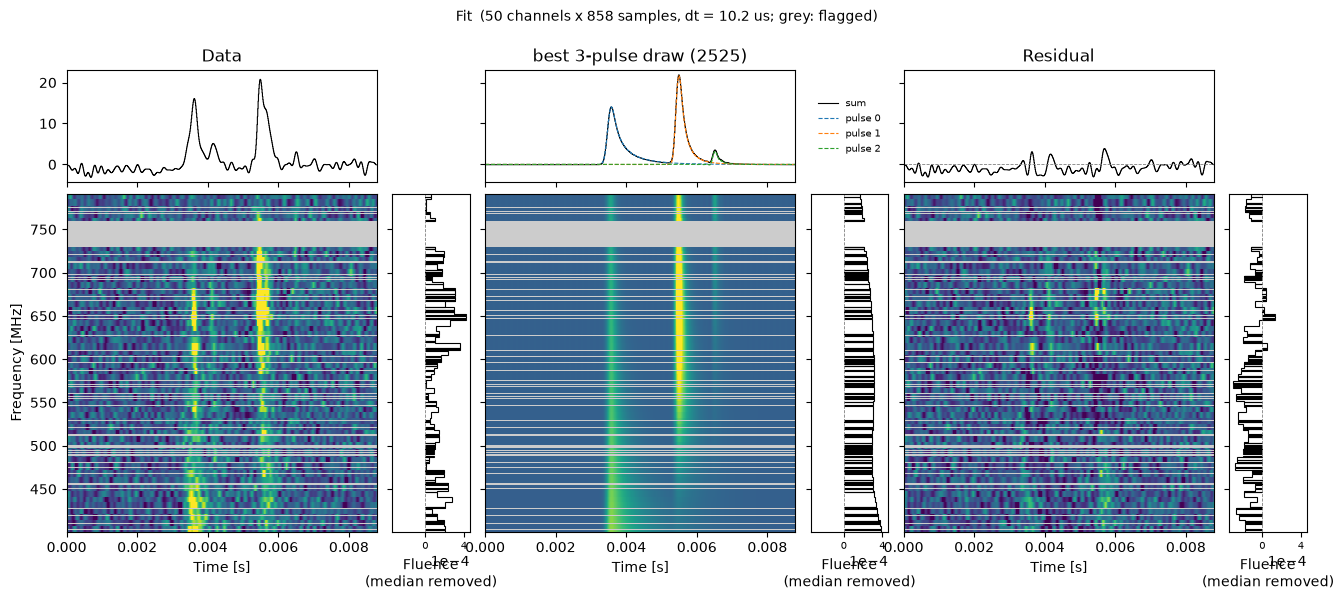

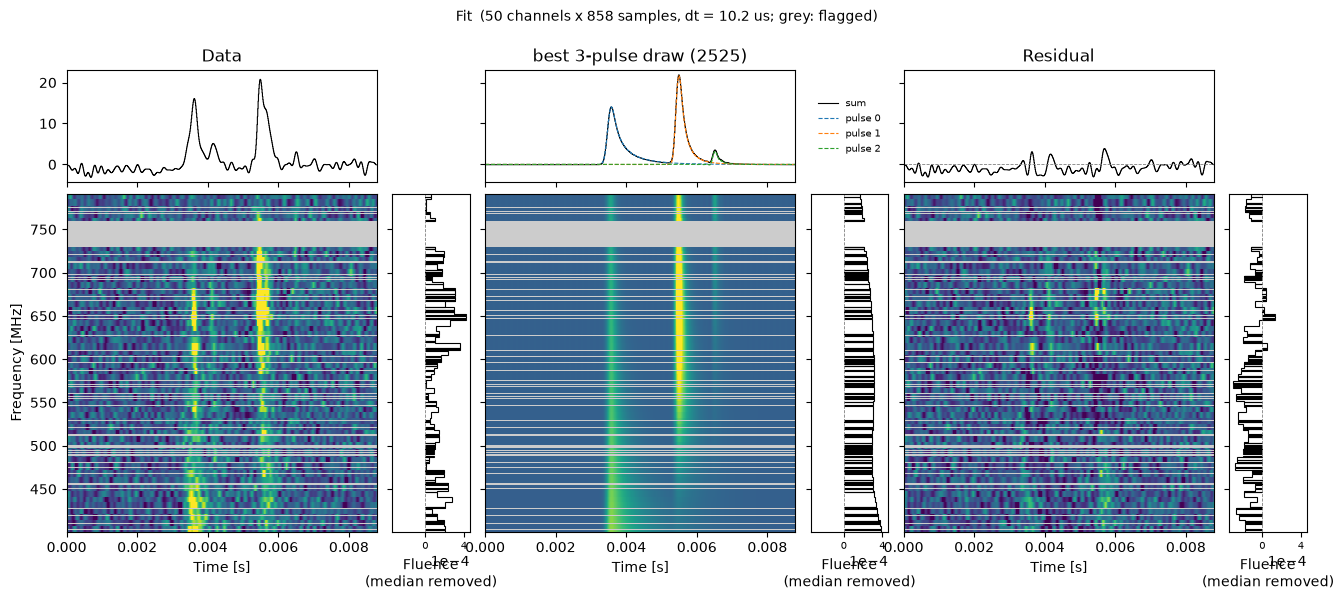

In [70]:
import numpy as np
from postprocess import pointwise_log_lik
from plotting import model_from_draw, plot_fit_TD

post = fits[3]["post"]
ll = pointwise_log_lik(burst, single_pulse_fn, {k: np.asarray(v)[None] for k, v in post.items()}, thin=1)[0].sum(-1)
d = int(np.argmax(ll))
M, Mp = model_from_draw(single_pulse_fn, post, d)
print(f"t [ms] {np.round(post['mean_arrival_time'][d] * 1e3, 3)}   A_snr {np.round(post['A_snr'][d], 1)}")
plot_fit_TD(burst, M, Mp, title_model=f"best 3-pulse draw ({d})")

draw 266: log-lik +0.0 vs best | t [ms] [3.485 5.41  7.14 ] | sigma [us] [  81.4   64.4 1025.2] | A_snr [44.9 59.9  6.9] | separation x [2.04 2.29 1.41]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


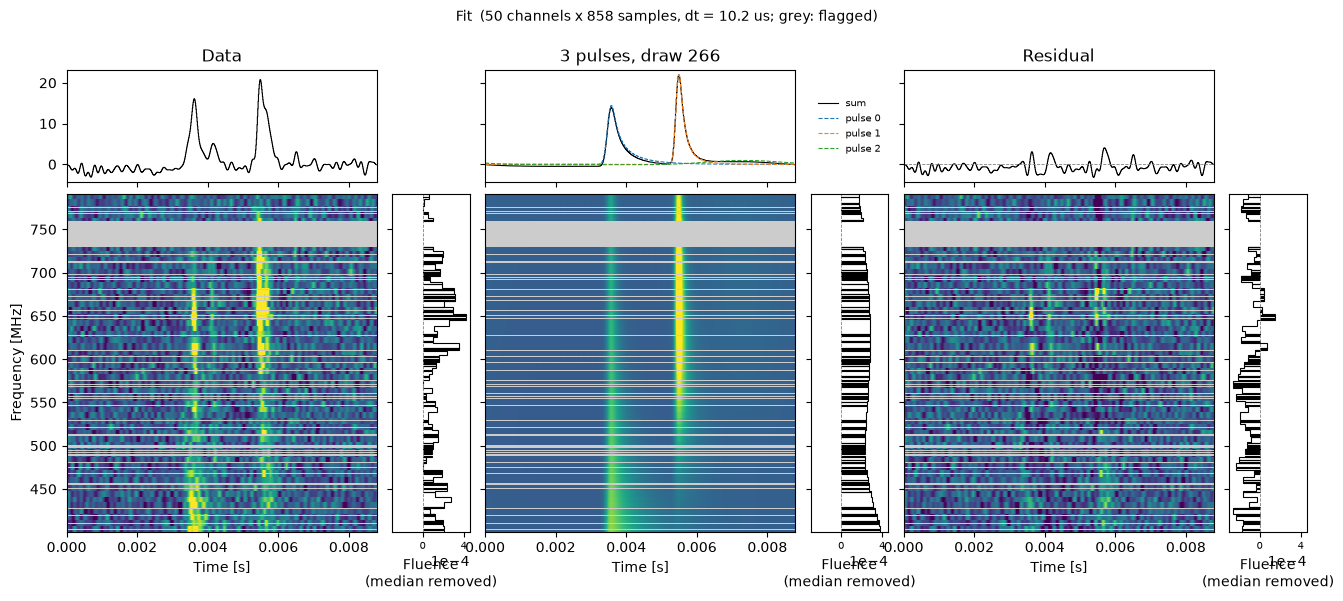

draw 851: log-lik -27.5 vs best | t [ms] [3.48  5.406 6.793] | sigma [us] [79.7 53.8 57.7] | A_snr [44.5 59.3  0.1] | separation x [1.88 3.24 3.83]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


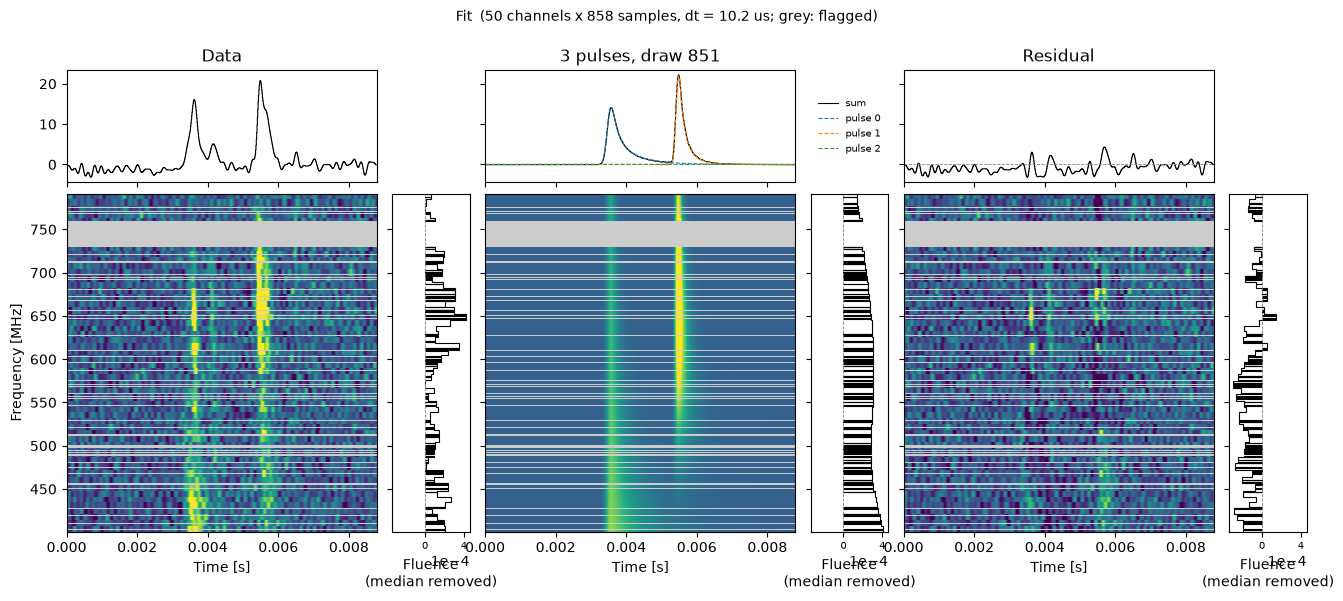

draw 638: log-lik -4.6 vs best | t [ms] [3.489 5.413 7.378] | sigma [us] [ 73.6  70.4 866.1] | A_snr [45.6 59.6  7.6] | separation x [2.09 2.7  1.86]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


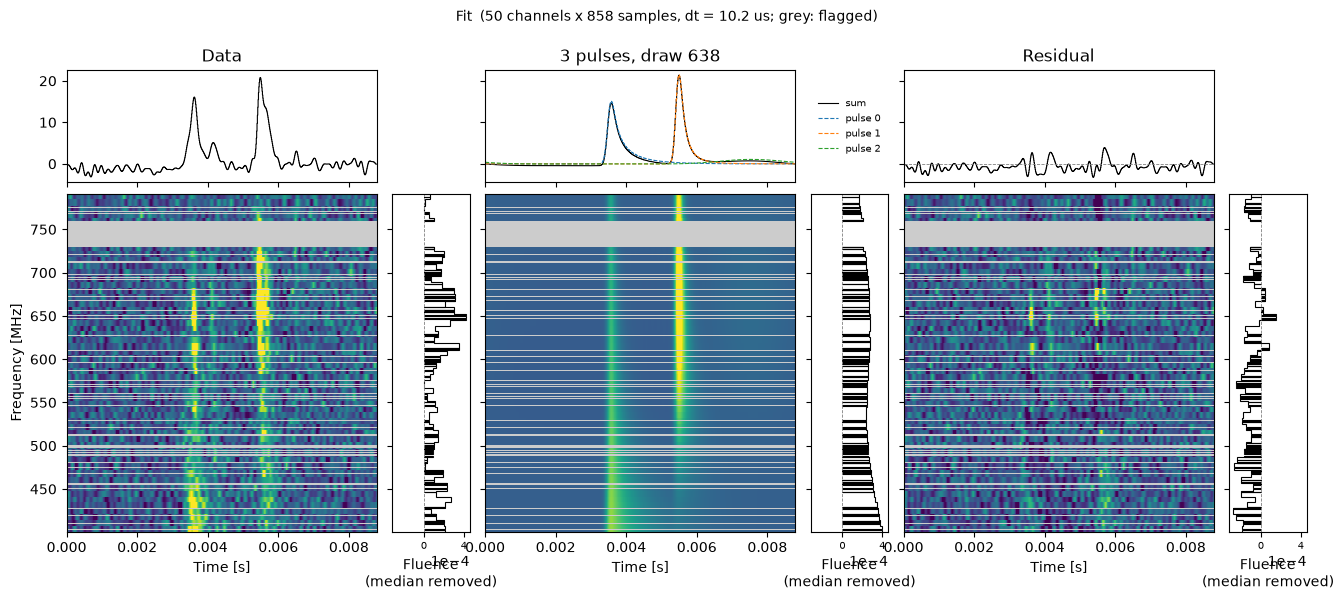

In [4]:
import numpy as np
from postprocess import pointwise_log_lik
from plotting import model_from_draw, plot_fit_TD

post = fits[3]["post"]
ll = pointwise_log_lik(burst, single_pulse_fn, {k: np.asarray(v)[None] for k, v in post.items()}, thin=1)[0].sum(-1)
rng = np.random.default_rng(0)
for d in [int(np.argmax(ll))] + list(rng.choice(len(ll), 2, replace=False)):
    M, Mp = model_from_draw(single_pulse_fn, post, d)
    sep = np.round(post["toa_separation"][d], 2) if "toa_separation" in post else "n/a"
    print(f"draw {d}: log-lik {ll[d] - ll.max():+.1f} vs best | t [ms] {np.round(post['mean_arrival_time'][d] * 1e3, 3)} | "
          f"sigma [us] {np.round(post['sigma'][d] * 1e6, 1)} | A_snr {np.round(post['A_snr'][d], 1)} | separation x {sep}")
    plot_fit_TD(burst, M, Mp, title_model=f"3 pulses, draw {d}")

# Computational diagnostics

In [ ]:
print("peak Memory usage in GB",jax.devices()[0].memory_stats()["peak_bytes_in_use"] / 1e9)